Dataset Shape: (5172, 3002)

First 5 Rows:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Null values in dat

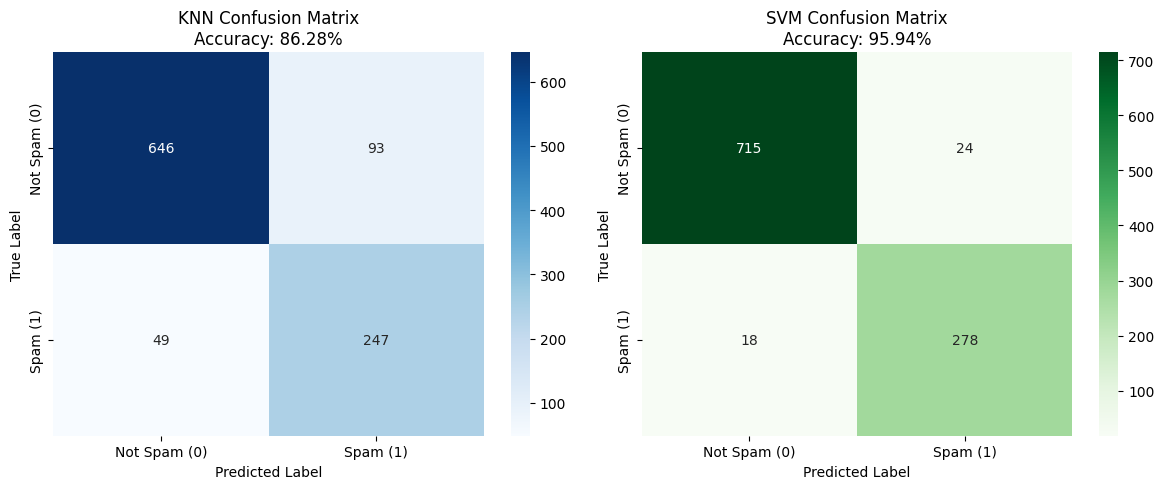


--- Final Performance Comparison ---
                   Algorithm Accuracy Score
   K-Nearest Neighbors (KNN)         86.28%
Support Vector Machine (SVM)         95.94%


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# -------------------------------------------------------------
# 1. Load Dataset
# -------------------------------------------------------------
# Dataset link: https://www.kaggle.com/datasets/balaka18/email-spam-classification-dataset-csv
df = pd.read_csv("emails.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

# -------------------------------------------------------------
# 2. Data Preprocessing & Feature/Target Split
# -------------------------------------------------------------
# Check for null values
print("\nNull values in dataset:", df.isnull().sum().sum())

# Clean missing values
df = df.dropna()
print("Dataset Shape after dropping NaNs:", df.shape)

# Dropping the 'Email No.' column since it is just an identifier
df = df.drop(columns=["Email No."])

# Separate feature matrix (X) and target vector (y)
# The last column 'Prediction' is the target (1: Spam, 0: Not Spam)
X = df.drop(columns=["Prediction"])
y = df["Prediction"]

# -------------------------------------------------------------
# 3. Train-Test Split
# -------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------------------------------------
# 4. Model 1: K-Nearest Neighbors (KNN)
# -------------------------------------------------------------
print("\n--- Training K-Nearest Neighbors Classifier ---")
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)
knn_acc = accuracy_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {knn_acc * 100:.2f}%")
print("\nKNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

# -------------------------------------------------------------
# 5. Model 2: Support Vector Machine (SVM)
# -------------------------------------------------------------
print("\n--- Training Support Vector Machine Classifier ---")
svm = SVC(kernel="linear", random_state=42)
svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)
svm_acc = accuracy_score(y_test, y_pred_svm)

print(f"SVM Accuracy: {svm_acc * 100:.2f}%")
print("\nSVM Classification Report:")
print(classification_report(y_test, y_pred_svm))

# -------------------------------------------------------------
# 6. Evaluation & Confusion Matrix Visualization
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# KNN Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Not Spam (0)", "Spam (1)"],
            yticklabels=["Not Spam (0)", "Spam (1)"])
axes[0].set_title(f"KNN Confusion Matrix\nAccuracy: {knn_acc * 100:.2f}%")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Not Spam (0)", "Spam (1)"],
            yticklabels=["Not Spam (0)", "Spam (1)"])
axes[1].set_title(f"SVM Confusion Matrix\nAccuracy: {svm_acc * 100:.2f}%")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 7. Comparison Summary
# -------------------------------------------------------------
comparison_df = pd.DataFrame({
    "Algorithm": ["K-Nearest Neighbors (KNN)", "Support Vector Machine (SVM)"],
    "Accuracy Score": [f"{knn_acc * 100:.2f}%", f"{svm_acc * 100:.2f}%"]
})

print("\n--- Final Performance Comparison ---")
print(comparison_df.to_string(index=False))